In [247]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    mean_absolute_error,
    mean_squared_error,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    f1_score
)

### 1

In [248]:
df = pd.read_csv('Car_Insurance_Claim 1.csv')
df.head()

,ID,AGE,GENDER,RACE,DRIVING_EXPERIENCE,EDUCATION,INCOME,CREDIT_SCORE,VEHICLE_OWNERSHIP,VEHICLE_YEAR,MARRIED,CHILDREN,POSTAL_CODE,ANNUAL_MILEAGE,VEHICLE_TYPE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS,OUTCOME
0,569520,65+,female,majority,0-9y,high school,upper class,0.629027,1,after 2015,0,1,10238,12000.0,sedan,0,0,0,0
1,750365,16-25,male,majority,0-9y,none,poverty,0.357757,0,before 2015,0,0,10238,16000.0,sedan,0,0,0,1
2,199901,16-25,female,majority,0-9y,high school,working class,0.493146,1,before 2015,0,0,10238,11000.0,sedan,0,0,0,0
3,478866,16-25,male,majority,0-9y,university,working class,0.206013,1,before 2015,0,1,32765,11000.0,sedan,0,0,0,0
4,731664,26-39,male,majority,10-19y,none,working class,0.388366,1,before 2015,0,0,32765,12000.0,sedan,2,0,1,1


 ستون آیدی که لازممون نمیشه رو پاک میکنیم

In [249]:
df = df.drop(columns=['ID'])


### 2

In [277]:
print("Shape:", df.shape)

Shape: (8149, 18)


الان 10 هزار نمونه با 18 ویژگی داریم

In [278]:
print(df.head())

     AGE  GENDER      RACE DRIVING_EXPERIENCE    EDUCATION         INCOME  \
0    65+  female  majority               0-9y  high school    upper class   
1  16-25    male  majority               0-9y         none        poverty   
2  16-25  female  majority               0-9y  high school  working class   
3  16-25    male  majority               0-9y   university  working class   
4  26-39    male  majority             10-19y         none  working class   

   CREDIT_SCORE  VEHICLE_OWNERSHIP VEHICLE_YEAR  MARRIED  CHILDREN  \
0      0.629027                  1   after 2015        0         1   
1      0.357757                  0  before 2015        0         0   
2      0.493146                  1  before 2015        0         0   
3      0.206013                  1  before 2015        0         1   
4      0.388366                  1  before 2015        0         0   

   POSTAL_CODE  ANNUAL_MILEAGE VEHICLE_TYPE  SPEEDING_VIOLATIONS  DUIS  \
0        10238         12000.0        seda

 نوع ستون ها 8 تا عددی هستن و دوتا فلوت و بقیه مقادیر غیر عددی هستند

In [279]:
print("shape:", df.shape)

print(df.dtypes)


shape: (8149, 18)
AGE                     object
GENDER                  object
RACE                    object
DRIVING_EXPERIENCE      object
EDUCATION               object
INCOME                  object
CREDIT_SCORE           float64
VEHICLE_OWNERSHIP        int64
VEHICLE_YEAR            object
MARRIED                  int64
CHILDREN                 int64
POSTAL_CODE              int64
ANNUAL_MILEAGE         float64
VEHICLE_TYPE            object
SPEEDING_VIOLATIONS      int64
DUIS                     int64
PAST_ACCIDENTS           int64
OUTCOME                  int64
dtype: object


<div align=center style='direction:rtl;'><pre>
        ستون CREDIT_SCORE تعداد 982 عدد مقدار گمشده داره.
        ستون ANNUAL_MILEAGE تعداد 957 عدد مقدار گمشده داره.


In [280]:
print(df.isnull().sum())

AGE                    0
GENDER                 0
RACE                   0
DRIVING_EXPERIENCE     0
EDUCATION              0
INCOME                 0
CREDIT_SCORE           0
VEHICLE_OWNERSHIP      0
VEHICLE_YEAR           0
MARRIED                0
CHILDREN               0
POSTAL_CODE            0
ANNUAL_MILEAGE         0
VEHICLE_TYPE           0
SPEEDING_VIOLATIONS    0
DUIS                   0
PAST_ACCIDENTS         0
OUTCOME                0
dtype: int64


در صورت سوال نگفته که با مقادیر مفقود چیکار کنیم
بنابر این یا با میانگین جایگزین میکنیم یا حذفشون میکنیم
که من حذف میکنم

In [281]:
df = df.dropna()

<div align=right style='direction:rtl;'><pre>
         اینجا بیشترین نوع ماشین سدان هست و اکثرا مال قبل از سال 2015 هستن
         و اینکه اکثرا راننده ها خانومن و اکثر رنج سنی بین 26 تا 39 سال هست 
         اکثرا تحصیلاتشون تا دبیرستانه درامدشون اکثرا بالاست 
         البته این بیشترین فراوانی ها بوده نه اینکه اکثرشون باشه 

In [282]:
print(df.describe(include='object'))

          AGE  GENDER      RACE DRIVING_EXPERIENCE    EDUCATION       INCOME  \
count    8149    8149      8149               8149         8149         8149   
unique      4       2         2                  4            3            4   
top     26-39  female  majority               0-9y  high school  upper class   
freq     2475    4084      7323               2864         3404         3588   

       VEHICLE_YEAR VEHICLE_TYPE  
count          8149         8149  
unique            2            2  
top     before 2015        sedan  
freq           5642         7761  


### 3 
جدا کردن ستون ها و باکس پلات

اینجا ستون های عددی و ستون های متنی رو جدا کردیم

In [256]:
target = 'OUTCOME'

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print(numeric_cols ,end='\n\n')

print(categorical_cols)

['CREDIT_SCORE', 'VEHICLE_OWNERSHIP', 'MARRIED', 'CHILDREN', 'POSTAL_CODE', 'ANNUAL_MILEAGE', 'SPEEDING_VIOLATIONS', 'DUIS', 'PAST_ACCIDENTS', 'OUTCOME']

['AGE', 'GENDER', 'RACE', 'DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME', 'VEHICLE_YEAR', 'VEHICLE_TYPE']


<div align=right style='direction:rtl;'><pre>
        حدود 68.88 درصد از افراد اعدای خسارت از بیمه نکردن و 
        حدود 31.12 ادعای خسارت بیمه کردن 
<br>
        این نشون دهنده اینه که دیتاستمون نامتوازنه  یعنی حدود 70 به 30 هست که در نمودار ستونی هم مشخصه

OUTCOME
0    5613
1    2536
Name: count, dtype: int64

Percentages:
OUTCOME
0    68.88
1    31.12
Name: proportion, dtype: float64


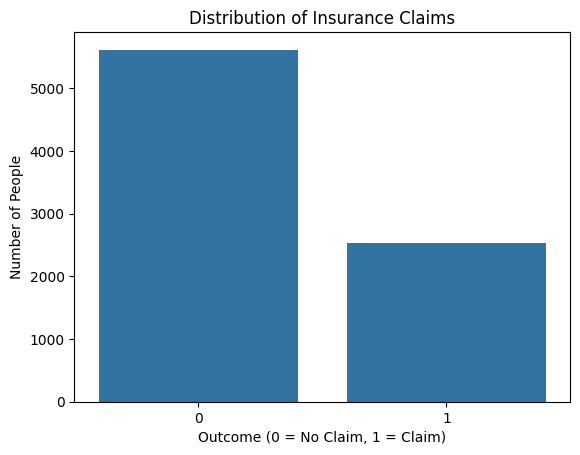

In [257]:
print(df[target].value_counts())
print("\nPercentages:")
print((df[target].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=df, x=target)
plt.title('Distribution of Insurance Claims')
plt.xlabel('Outcome (0 = No Claim, 1 = Claim)')
plt.ylabel('Number of People')
plt.show()

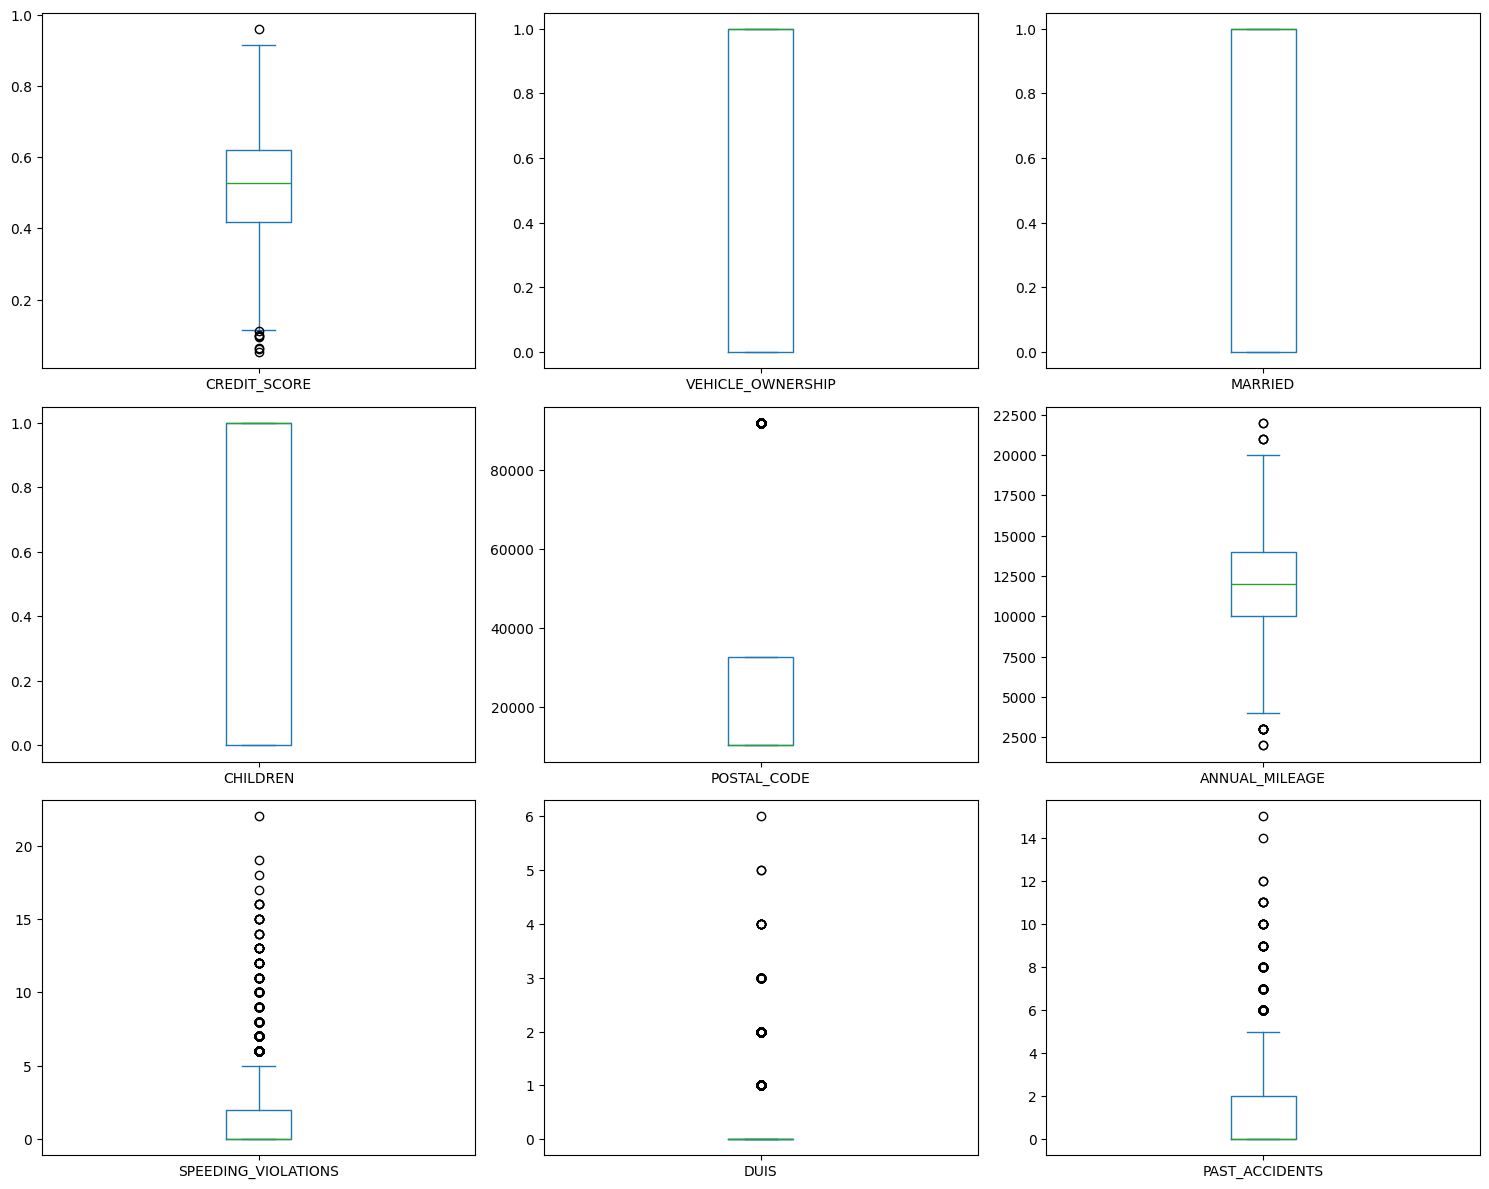

In [258]:
numeric_cols = [
    c for c in df.select_dtypes(include=np.number).columns
    if c != target
]

df[numeric_cols].plot(
    kind='box',
    subplots=True,
    layout=(-1, 3),
    figsize=(15, 12),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

<div align=center style='direction:rtl;'><pre>
این باکس پلات ها نشون میدن که توزیع ویژگی ها یکسان نیست 
<br>
ANNUAL_MILEAGE و CREDIT_SCORE  مقادیر پرت دارن
<br>
و متغییر ها DUIS و SPEEDING_VIOLATIONS و PAST_ACCIDENTS 
<br>
مقادیرشون کوچیک هست و فقط چندین مقدار بزرگ پرت دارن

### 4 
مقایسه گروه 0 با گروه 1 با باکس پلات

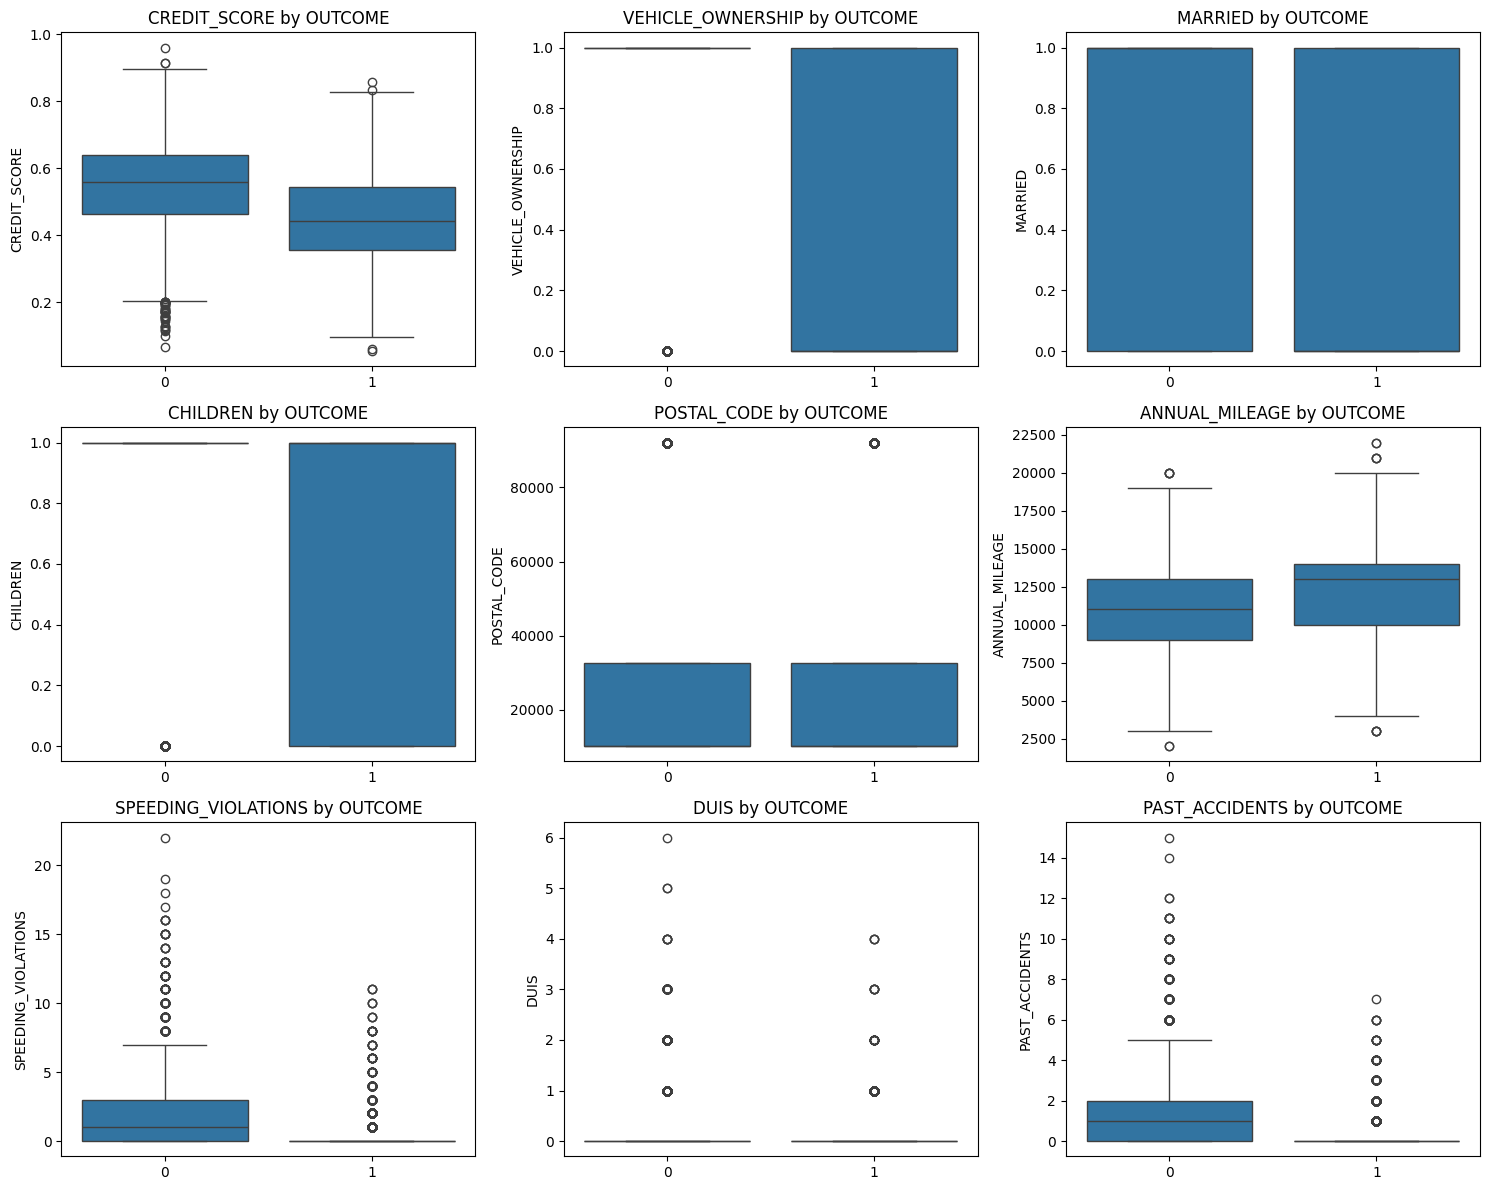

In [259]:
n_cols = 3
n_rows = (len(numeric_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=df, x=target, y=col, ax=axes[i])
    axes[i].set_title(f'{col} by OUTCOME')
    axes[i].set_xlabel('')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


<div align=center style='direction:rtl;'><pre>
میانه credit_score در گروهی که ادعای خسارت کردن پایین تر و  و در annual_mileage بیشتر هست
 بنابراین ممکنه که این ویژگی با نتیجه ارتباط داشته باشن

### 7 
تقسیم ترین و تست

طبق گفته اقای حاجی عباسی باید اول تست و ترین و جدا کنیم تا از نشت داده جلوگیری شه

In [260]:
X = df.drop(columns=[target])
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

OUTCOME
0    0.689
1    0.311
Name: proportion, dtype: float64
OUTCOME
0    0.689
1    0.311
Name: proportion, dtype: float64


### 3
حذف داده های پرت روی فقط داده ترین

In [261]:
cont_cols = ['CREDIT_SCORE', 'ANNUAL_MILEAGE']

mask = pd.Series(True, index=X_train.index)
for col in cont_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    mask &= (X_train[col] >= Q1 - 1.5 * IQR) & (X_train[col] <= Q3 + 1.5 * IQR)

X_train_clean, y_train_clean = X_train[mask], y_train[mask]

print("ردیف‌های ترین قبل از حذف پرت:", len(X_train))
print("ردیف‌های ترین بعد از حذف پرت:", len(X_train_clean))

ردیف‌های ترین قبل از حذف پرت: 6519
ردیف‌های ترین بعد از حذف پرت: 6498


### 5
بالانس داده اما فقط روی داده ترین  یا همون آموزش

In [262]:
n = y_train_clean.value_counts().min()

idx = y_train_clean.groupby(y_train_clean).sample(
    n=n, random_state=42
).index

X_train_bal, y_train_bal = X_train_clean.loc[idx], y_train_clean.loc[idx]

print(y_train_bal.value_counts())

OUTCOME
0    2018
1    2018
Name: count, dtype: int64


هر دو کلاس ۲۰۱۸ تا شدن، یعنی روی ترین ۴۰۳۶ ردیف متعادل داریم.

### 6
پیش پردازش میانگین و مقیاس و وان هات

In [263]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imp', SimpleImputer(strategy='mean')),
        ('sc', MinMaxScaler())
    ]), numeric_features),

    ('cat', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('oh', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

<div align=center style='direction:rtl;'><pre>

مقدار گمشده با میانگین پر می‌شه، بعد با MinMaxScaler همه‌ی ستون‌ها به بازه‌ی ۰ تا ۱ میرت

### 8
آموزش دو مدل

In [264]:
svm_model = Pipeline([
    ('prep', preprocessor),
    ('svc', SVC(kernel='linear', C=1))
])

tree_model = Pipeline([
    ('prep', preprocessor),
    ('tree', DecisionTreeClassifier(max_depth=5))
])

svm_model.fit(X_train_bal, y_train_bal)
tree_model.fit(X_train_bal, y_train_bal)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer()),
                                                                  ('sc',
                                                                   MinMaxScaler())]),
                                                  ['CREDIT_SCORE',
                                                   'VEHICLE_OWNERSHIP',
                                                   'MARRIED', 'CHILDREN',
                                                   'POSTAL_CODE',
                                                   'ANNUAL_MILEAGE',
                                                   'SPEEDING_VIOLATIONS',
                                                   'DUIS', 'PAST_ACCIDENTS']),
                                                 ('cat',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('oh',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['AGE', 'GENDER', 'RACE',
                                                   'DRIVING_EXPERIENCE',
                                                   'EDUCATION', 'INCOME',
                                                   'VEHICLE_YEAR',
                                                   'VEHICLE_TYPE'])])),
                ('tree', DecisionTreeClassifier(max_depth=5))])

ارزیابی و جدول خطا

SVM

Accuracy: 0.8117
Balanced Accuracy: 0.8173
F1: 0.7333
MAE: 0.1883
MSE: 0.1883
              precision    recall  f1-score   support

           0       0.91      0.80      0.85      1123
           1       0.66      0.83      0.73       507

    accuracy                           0.81      1630
   macro avg       0.78      0.82      0.79      1630
weighted avg       0.83      0.81      0.82      1630



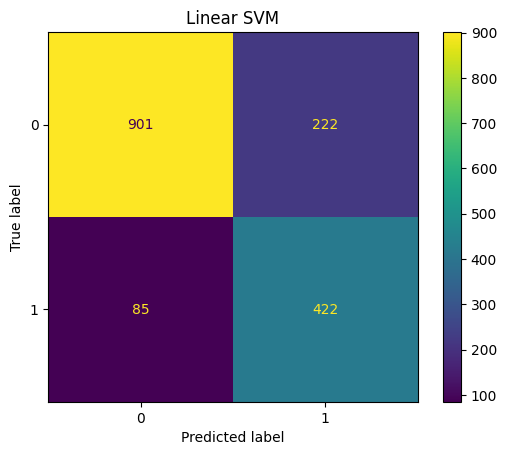

In [265]:
pred = svm_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, pred), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, pred), 4))
print("F1:", round(f1_score(y_test, pred), 4))
print("MAE:", round(mean_absolute_error(y_test, pred), 4))
print("MSE:", round(mean_squared_error(y_test, pred), 4))
print(classification_report(y_test, pred))

ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.title("Linear SVM")
plt.show()

<div align=center style='direction:rtl;'><pre>
901 نمونه از کلاس صفر درست تشخیص داده شده
422 نمونه هم از کلاس 1 درست تشخیص شده
اما 85 تا از کلاس 1 غلط تشخیص شده در صورتی که ادعا داشتن بدون ادعا تشخیص شده
و 222 تا هم از کلاس  0 غلط تشخیص شده و ادعا دار تشخیص شده

یعنی مدل بیشتر خطاش هشدار الکیه




درخت تصمیم

Accuracy: 0.8092
Balanced Accuracy: 0.8231
F1: 0.7371
MAE: 0.1908
MSE: 0.1908
              precision    recall  f1-score   support

           0       0.93      0.79      0.85      1123
           1       0.64      0.86      0.74       507

    accuracy                           0.81      1630
   macro avg       0.79      0.82      0.79      1630
weighted avg       0.84      0.81      0.82      1630



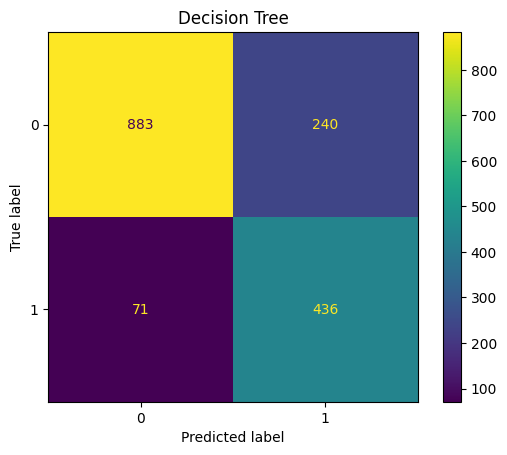

In [266]:
pred = tree_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, pred), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, pred), 4))
print("F1:", round(f1_score(y_test, pred), 4))
print("MAE:", round(mean_absolute_error(y_test, pred), 4))
print("MSE:", round(mean_squared_error(y_test, pred), 4))
print(classification_report(y_test, pred))

ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.title("Decision Tree")
plt.show()

<div align=center style='direction:rtl;'><pre>
883 نمونه از کلاس صفر درست تشخیص داده شده
436 نمونه هم از کلاس 1 درست تشخیص شده
اما 71 تا از کلاس 1 غلط تشخیص شده در صورتی که ادعا داشتن بدون ادعا تشخیص شده
و 240 تا هم از کلاس  0 غلط تشخیص شده و ادعا دار تشخیص شده




<div align=center style='direction:rtl;'><pre>
mse , mae هردو مدل تفاوت کمی باهم دارن و دقت هردو حدود 81 درصد هست

In [267]:
y_pred_svm = svm_model.predict(X_test)
y_pred_tree = tree_model.predict(X_test)

In [268]:
results = pd.DataFrame({
    'Model': ['Linear SVM', 'Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_tree)
    ],
    'Balanced Acc': [
        balanced_accuracy_score(y_test, y_pred_svm),
        balanced_accuracy_score(y_test, y_pred_tree)
    ],
    'F1': [
        f1_score(y_test, y_pred_svm, zero_division=0),
        f1_score(y_test, y_pred_tree, zero_division=0)
    ]
})

print(results.round(4))

           Model  Accuracy  Balanced Acc      F1
0     Linear SVM    0.8117        0.8173  0.7333
1  Decision Tree    0.8092        0.8231  0.7371


<div align=center style='direction:rtl;'><pre>
دو مدل تقریباً هم‌سطح هستن. درخت balanced accuracy و F1 بهتری داره

### 9
اهمیت ویژگی

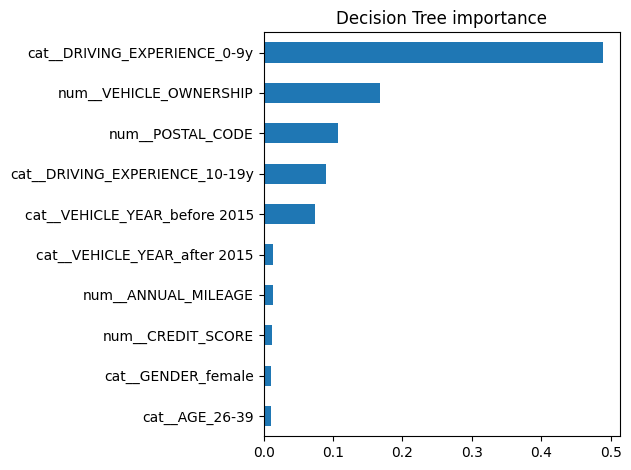

cat__DRIVING_EXPERIENCE_0-9y      2.045071
num__VEHICLE_OWNERSHIP           -1.537109
num__POSTAL_CODE                  1.456768
cat__DRIVING_EXPERIENCE_30y+     -1.358070
cat__DRIVING_EXPERIENCE_20-29y   -1.071371
num__ANNUAL_MILEAGE               0.864893
cat__VEHICLE_YEAR_before 2015     0.763861
cat__VEHICLE_YEAR_after 2015     -0.763861
num__SPEEDING_VIOLATIONS          0.449563
num__PAST_ACCIDENTS              -0.419223
dtype: float64


In [269]:
names = tree_model.named_steps['prep'].get_feature_names_out()

imp = pd.Series(
    tree_model.named_steps['tree'].feature_importances_,
    index=names
)

imp.sort_values().tail(10).plot(kind='barh', title='Decision Tree importance')
plt.tight_layout()
plt.show()

svc = svm_model.named_steps['svc']
coef = svc.coef_.ravel()

s = pd.Series(coef, index=names)
print(s.reindex(s.abs().sort_values(ascending=False).index).head(10))

<div align=center style='direction:rtl;'><pre>
هر دو مدل ویژگی‌های
<br>
DRIVING_EXPERIENCE_0-9y، VEHICLE_OWNERSHIP، POSTAL_CODE و VEHICLE_YEAR 
<br>
رو مهم دونستن. بااین‌حال، SVM به ویژگی‌هایی مثل
<br>
  ANNUAL_MILEAGE و SPEEDING_VIOLATIONS 
<br>
  هم اهمیت داده، درحالیکه درخت تصمیم اهمیت کمتری بهشون داده

### 10 
تنظیم SVM 

با 

grid search

In [270]:
grid = GridSearchCV(
    svm_model,
    param_grid={'svc__C': [0.01, 0.1, 1, 10, 100]},
    scoring='f1', cv=5, n_jobs=-1
)

grid.fit(X_train_bal, y_train_bal)

print(grid.best_params_, round(grid.best_score_, 4))
best_svm = grid.best_estimator_

{'svc__C': 0.1} 0.8329


### مقایسه نهایی

In [271]:
y_pred_svm = svm_model.predict(X_test)
y_pred_tree = tree_model.predict(X_test)
y_pred_best = best_svm.predict(X_test)

In [272]:
final_results = pd.DataFrame({
    'Model': ['Linear SVM', 'Decision Tree', 'Tuned SVM'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_best)
    ],
    'Balanced Acc': [
        balanced_accuracy_score(y_test, y_pred_svm),
        balanced_accuracy_score(y_test, y_pred_tree),
        balanced_accuracy_score(y_test, y_pred_best)
    ],
    'F1': [
        f1_score(y_test, y_pred_svm),
        f1_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_best)
    ],
    'MAE': [
        mean_absolute_error(y_test, y_pred_svm),
        mean_absolute_error(y_test, y_pred_tree),
        mean_absolute_error(y_test, y_pred_best)
    ],
    'MSE': [
        mean_squared_error(y_test, y_pred_svm),
        mean_squared_error(y_test, y_pred_tree),
        mean_squared_error(y_test, y_pred_best)
    ]
})

print("Final comparison:")
print(final_results.round(4))

Final comparison:
           Model  Accuracy  Balanced Acc      F1     MAE     MSE
0     Linear SVM    0.8117        0.8173  0.7333  0.1883  0.1883
1  Decision Tree    0.8092        0.8231  0.7371  0.1908  0.1908
2      Tuned SVM    0.8104        0.8175  0.7329  0.1896  0.1896


<div align=center style='direction:rtl;'><pre>هر سه مدل تقریباً یکسانن

<div align=center style='direction:rtl;'><pre>

Tuned SVM با C=0.1 روی تست کمی بدتر از Linear SVM با C=1 شد 
 یعنی تنظیم C تقریباً اثری نداشت

<div align=center style='direction:rtl;'><pre>
بنظرم مدل درخت برای این دیتاست بهتره

<div align=center style='direction:rtl;'><pre>
کلی بخوایم نگا کنیم خطای درخت بیشتره ولی تفاوتشون خیلی کمخ

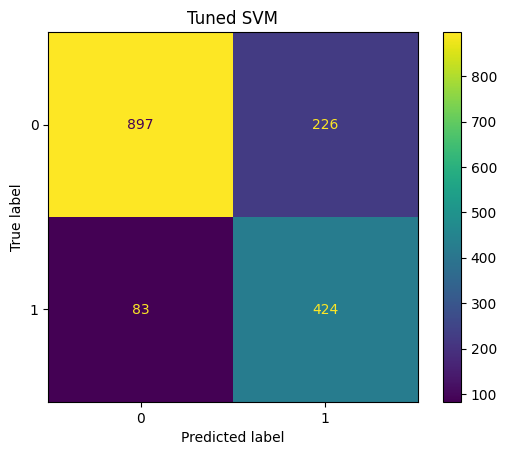

In [273]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best)
plt.title("Tuned SVM")
plt.show()

In [274]:
param_grid_svm = [
    {'svc__kernel': ['linear'],
     'svc__C': [0.01, 0.1, 1, 10, 100]},
    {'svc__kernel': ['rbf'],
     'svc__C': [0.1, 1, 10, 100],
     'svc__gamma': ['scale', 1, 0.1, 0.01, 0.001]}
]

grid_svm = GridSearchCV(svm_model, param_grid_svm,
                        scoring='f1', cv=5, n_jobs=-1, verbose=1)
grid_svm.fit(X_train_bal, y_train_bal)

print(grid_svm.best_params_)
print(round(grid_svm.best_score_, 4))
best_svm = grid_svm.best_estimator_

res = pd.DataFrame(grid_svm.cv_results_)[['params', 'mean_test_score', 'rank_test_score']]
print(res.sort_values('rank_test_score').head(10))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
{'svc__C': 0.1, 'svc__kernel': 'linear'}
0.8329
                                               params  mean_test_score  \
1            {'svc__C': 0.1, 'svc__kernel': 'linear'}         0.832857   
24  {'svc__C': 100, 'svc__gamma': 0.001, 'svc__ker...         0.831331   
4            {'svc__C': 100, 'svc__kernel': 'linear'}         0.830558   
13  {'svc__C': 1, 'svc__gamma': 0.01, 'svc__kernel...         0.829887   
3             {'svc__C': 10, 'svc__kernel': 'linear'}         0.829768   
2              {'svc__C': 1, 'svc__kernel': 'linear'}         0.829497   
18  {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kerne...         0.828827   
19  {'svc__C': 10, 'svc__gamma': 0.001, 'svc__kern...         0.828391   
17  {'svc__C': 10, 'svc__gamma': 0.1, 'svc__kernel...         0.827124   
23  {'svc__C': 100, 'svc__gamma': 0.01, 'svc__kern...         0.826692   

    rank_test_score  
1                 1  
24                2  
4        

<div align=center style='direction:rtl;'><pre>
بین ۲۵ ترکیب (خطی و rbf) بهترین، SVM خطی با C=0.1 شد
ده ترکیب برتر کمتر از یک درصد اختلاف داشتن و rbf برتری نشون نداد، پس مرز تصمیم تقریباً خطیه

In [275]:
param_grid_tree = {
    'tree__max_depth': [3, 5, 7, 10, None],
    'tree__min_samples_leaf': [1, 5, 20, 50],
    'tree__criterion': ['gini', 'entropy']
}

grid_tree = GridSearchCV(tree_model, param_grid_tree,
                         scoring='f1', cv=5, n_jobs=-1, verbose=1)
grid_tree.fit(X_train_bal, y_train_bal)

print(grid_tree.best_params_)
print(round(grid_tree.best_score_, 4))
best_tree = grid_tree.best_estimator_

res_t = pd.DataFrame(grid_tree.cv_results_)[['params', 'mean_test_score', 'rank_test_score']]
print(res_t.sort_values('rank_test_score').head(10))

Fitting 5 folds for each of 40 candidates, totalling 200 fits
{'tree__criterion': 'entropy', 'tree__max_depth': 5, 'tree__min_samples_leaf': 5}
0.8389
                                               params  mean_test_score  \
25  {'tree__criterion': 'entropy', 'tree__max_dept...         0.838946   
26  {'tree__criterion': 'entropy', 'tree__max_dept...         0.837490   
4   {'tree__criterion': 'gini', 'tree__max_depth':...         0.837487   
24  {'tree__criterion': 'entropy', 'tree__max_dept...         0.837383   
5   {'tree__criterion': 'gini', 'tree__max_depth':...         0.837005   
6   {'tree__criterion': 'gini', 'tree__max_depth':...         0.836460   
30  {'tree__criterion': 'entropy', 'tree__max_dept...         0.831288   
27  {'tree__criterion': 'entropy', 'tree__max_dept...         0.830777   
10  {'tree__criterion': 'gini', 'tree__max_depth':...         0.830714   
7   {'tree__criterion': 'gini', 'tree__max_depth':...         0.830453   

    rank_test_score  
25          

<div align=center style='direction:rtl;'><pre>
بین ۴۰ ترکیب، بهترین با entropy و عمق ۵ و min_samples_leaf=5 و F1 بود
 اختلاف ترکیب‌های برتر ناچیزه و محدود کردن عمق جلوی بیش‌برازش رو گرفت.

In [276]:
y_pred_svm = svm_model.predict(X_test)
y_pred_tree = tree_model.predict(X_test)
y_pred_best_svm = best_svm.predict(X_test)
y_pred_best_tree = best_tree.predict(X_test)

preds = {
    'Linear SVM': y_pred_svm,
    'Decision Tree': y_pred_tree,
    'Tuned SVM': y_pred_best_svm,
    'Tuned Tree': y_pred_best_tree
}

final_results = pd.DataFrame({
    'Model': list(preds.keys()),
    'Accuracy': [accuracy_score(y_test, p) for p in preds.values()],
    'Balanced Acc': [balanced_accuracy_score(y_test, p) for p in preds.values()],
    'F1': [f1_score(y_test, p) for p in preds.values()],
    'MAE': [mean_absolute_error(y_test, p) for p in preds.values()],
    'MSE': [mean_squared_error(y_test, p) for p in preds.values()]
})
print(final_results.round(4))

           Model  Accuracy  Balanced Acc      F1     MAE     MSE
0     Linear SVM    0.8117        0.8173  0.7333  0.1883  0.1883
1  Decision Tree    0.8092        0.8231  0.7371  0.1908  0.1908
2      Tuned SVM    0.8104        0.8175  0.7329  0.1896  0.1896
3     Tuned Tree    0.8092        0.8231  0.7371  0.1908  0.1908


<div align=center style='direction:rtl;'><pre>
هر چهار مدل روی تست accuracy حدود ۰.۸۱ و F1 حدود ۰.۷۳ گرفتن و اختلافشون چند نمونه از ۱۶۳۰ تاست.
 تنظیم پارامتر بهبودی نداد و درخت فقط به‌خاطر recall بالاتر کلاس ۱ کمی مناسب‌تره